## 运行环境准备

请在当前 notebook 内核中安装依赖。使用 `%pip` 可以确保安装到正在运行此 notebook 的 Python 环境：

```python
%pip install torch torchvision nltk pandas numpy scikit-learn matplotlib seaborn kagglehub
```

安装完成后重启内核，再从头运行单元格。

## 0. 导入依赖

除 PyTorch 外，还使用 `random` / NumPy 控制随机种子、`Counter` 限制词表规模，使用 NLTK 做批量词性标注和词形还原。

In [ ]:
import html
import random
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import Dataset, DataLoader

import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer


## 1. 固定随机种子

固定 Python、NumPy、PyTorch 和数据划分的随机状态，方便复现实验。

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


## 2. 检查 NLTK 资源

本项目已在 nltk_data 目录中提供 wordnet、averaged_perceptron_tagger_eng 和 stopwords。下面的代码会优先检查该目录，也会检查 NLTK 默认目录；无需运行时联网下载。

若检查仍提示缺少资源，确认 nltk_data 文件夹与 notebook 位于同一项目目录，并从头重新运行单元格。


In [3]:
from pathlib import Path

NLTK_DATA_DIR = Path("nltk_data")
if NLTK_DATA_DIR.exists():
    nltk.data.path.insert(0, str(NLTK_DATA_DIR.resolve()))

required_nltk_resources = (
    "corpora/wordnet",
    "taggers/averaged_perceptron_tagger_eng",
    "corpora/stopwords",
)
missing_nltk_resources = []
for resource in required_nltk_resources:
    try:
        nltk.data.find(resource)
    except LookupError:
        missing_nltk_resources.append(resource)

if missing_nltk_resources:
    raise LookupError(
        "Missing NLTK resources: " + ", ".join(missing_nltk_resources)
        + ". Place them in ./nltk_data or an NLTK data directory."
    )

print("NLTK resources are available.")


NLTK resources are available.


## 总览：从 CSV 到预测概率

```text
读取与检查标签
   ↓ 分层划分：训练 80% / 验证 10% / 测试 10%
仅用训练集拟合词表（最多 50,000 词）
   ↓ 保留否定词、清理 HTML、按句批量词性标注
编码（MAX_LEN=256，未登录词映射到 <UNK>）
   ↓ 每个 batch 动态补齐并打包变长序列
Embedding → LSTM → Dropout → Linear logits
   ↓ BCEWithLogitsLoss、梯度裁剪、验证集早停
最佳验证 checkpoint → 最终测试集分类报告
```

测试集只在训练和模型选择完成后评估一次。

## 3. 定位数据文件

优先读取 notebook 同目录中的 `IMDB_Dataset.csv`，这样本地运行无需联网。只有本地文件不存在时，才通过 KaggleHub 下载数据集。


In [4]:
from pathlib import Path

DATA_FILE = Path("IMDB_Dataset.csv")
if DATA_FILE.exists():
    path = str(DATA_FILE)
else:
    path = kagglehub.dataset_download("rehanliaqat17/imbd-dataset") + "/IMDB_Dataset.csv"

print("Path to dataset files:", Path(path).resolve())


Path to dataset files: D:\project\python_study\Sentiment-Classification-PyTorch-IMBD\IMDB_Dataset.csv


## 4. 读取 CSV

数据表包含 `review`（影评文本）和 `sentiment`（情感标签）两列。查看前五行可以快速确认列名和文件是否正确解析。


In [5]:
df = pd.read_csv(path)
df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 5. 编码情感标签

显式将 positive 映射为 1、negative 映射为 0。转换可重复运行；遇到未知标签或缺失值时会报出清晰错误，不会静默生成 NaN。


In [6]:
df['sentiment'] = df['sentiment'].replace({
    "positive": 1,
    "negative": 0
})
invalid_labels = ~df['sentiment'].isin([0, 1])
if invalid_labels.any():
    values = df.loc[invalid_labels, 'sentiment'].unique().tolist()
    raise ValueError(f"Unexpected or missing sentiment labels: {values}")
df['sentiment'] = df['sentiment'].astype('int64')
df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


## 6. 统计评论长度

这里按空白切分并统计词数，标点仍可能附着在词上，因此只是粗略估计。长度分布用于选择后续的 `MAX_LEN`，这列不作为模型输入。


In [7]:
df['length'] = df['review'].apply(lambda x: len(x.split()))


## 6.1 EDA：探索性数据分析

先看两个与建模直接相关的分布：评论长度分布与标签分布。

## EDA：评论长度分布

绘图库仅在探索性分析中使用，因此在此处就近导入。直方图展示各长度区间的评论数量，KDE 曲线展示总体分布趋势。


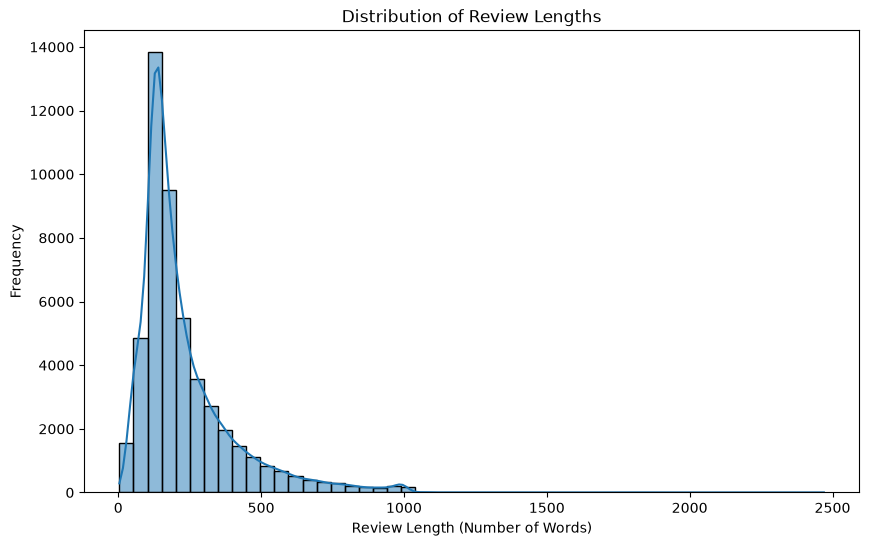

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['length'], bins=50, kde=True)
plt.title('Distribution of Review Lengths')
plt.xlabel('Review Length (Number of Words)')
plt.ylabel('Frequency')
plt.show()


### 6.2 EDA 的两点结论

- **长度分布**：平均约 231 词，中位数 173 词，长尾一直拖到 2,470 词。
  约 29% 的评论超过 256 词，因此后面统一截断到 **256 词**：
  既保留了大部分信息，又把序列长度（≈ LSTM 的计算量）控制住。
- **标签分布**：正面 / 负面各 25,000 条，**完全均衡**，
  所以 accuracy 就是合理的主指标，不需要重采样或不平衡处理。

## EDA：标签分布

`countplot` 统计每个标签的样本数。数据预期正面和负面评论各 25,000 条，类别均衡时可将 accuracy 作为主要指标。


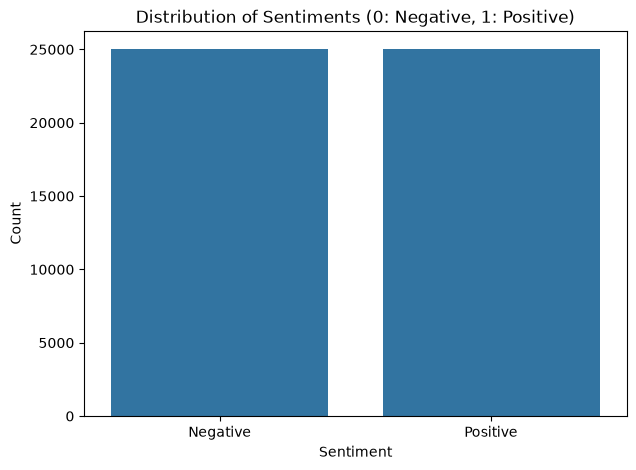

In [9]:
plt.figure(figsize=(7, 5))
sns.countplot(x='sentiment', data=df)
plt.title('Distribution of Sentiments (0: Negative, 1: Positive)')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.show()


## 7. 词性感知的词形还原

每条评论调用一次 `nltk.pos_tag(tokens)`，再按 Penn Treebank 标签映射 WordNet 词性，避免对每个单词重复启动标注器。

In [ ]:
# POS tagging is performed once per review in the preprocessing cell below.


## 8. 文本预处理与训练集词表

先分层划分原始文本，再只用训练集构建词表。预处理会清理 HTML、保留否定词，并对整句批量词性标注；词表最多保留 50,000 项（包含 `<PAD>` 与 `<UNK>`）。

In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))
stop_words -= {
    "no", "nor", "not", "ain", "aren't", "couldn't", "didn't", "doesn't",
    "don't", "hadn't", "hasn't", "haven't", "isn't", "mightn't", "mustn't",
    "needn't", "shan't", "shouldn't", "wasn't", "weren't", "won't", "wouldn't",
}
TOKEN_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+")
TAG_MAP = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}


def preprocess_text(text: str):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    tokens = [token for token in TOKEN_PATTERN.findall(text) if token not in stop_words]
    if not tokens:
        return []
    tagged_tokens = nltk.pos_tag(tokens)
    return [
        lemmatizer.lemmatize(token, TAG_MAP.get(tag[0].upper(), wordnet.NOUN))
        for token, tag in tagged_tokens
    ]


texts = df["review"].fillna("").astype(str).tolist()
labels_all = df["sentiment"].to_numpy(dtype=np.int64)
train_texts, holdout_texts, y_train_values, y_holdout_values = train_test_split(
    texts, labels_all, test_size=0.2, random_state=SEED, stratify=labels_all
)
val_texts, test_texts, y_val_values, y_test_values = train_test_split(
    holdout_texts, y_holdout_values, test_size=0.5, random_state=SEED,
    stratify=y_holdout_values,
)

tokenized_train = [preprocess_text(text) for text in train_texts]
tokenized_val = [preprocess_text(text) for text in val_texts]
tokenized_test = [preprocess_text(text) for text in test_texts]

MAX_VOCAB_SIZE = 50_000
MIN_FREQ = 2
word_counts = Counter(token for review in tokenized_train for token in review)
vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in word_counts.most_common(MAX_VOCAB_SIZE - len(vocab)):
    if count < MIN_FREQ:
        break
    vocab[word] = len(vocab)
vocab_size = len(vocab)
idx_to_vocab = {idx: word for word, idx in vocab.items()}
print(f"Split sizes: train={len(train_texts)}, val={len(val_texts)}, test={len(test_texts)}")
print(f"Vocabulary size: {vocab_size}")


### 8.1 预处理与评估约定

- 否定词会保留，以免把 “not good” 简化成 “good”。
- 词表只从训练集构建；验证集和测试集中的未登录词编码为 `<UNK>`。
- 按 batch 动态补齐，避免所有样本都占用固定的 256 个位置。
- 验证集用于选择 checkpoint 和早停；测试集只在训练结束后评估一次。

## 9. 词表查找

编码时，词表外的词映射到 `<UNK>`；反向查找使用预先建立的字典，查询复杂度为常数级。

In [ ]:
def encoder_decoder(key: str | int):
    if isinstance(key, str):
        return vocab.get(key, vocab["<UNK>"])
    if isinstance(key, int):
        return idx_to_vocab[key]
    raise TypeError("key must be a string token or integer id")


## 10. 编码与截断

每条评论最多保留 256 个词元。若清洗后没有词元，使用 `<UNK>` 保证 LSTM 至少收到一个位置。

In [ ]:
MAX_LEN = 256


def encode_reviews(corpus):
    encoded = []
    for review in corpus:
        tokens = review[:MAX_LEN] or ["<UNK>"]
        encoded.append(torch.tensor([encoder_decoder(token) for token in tokens], dtype=torch.long))
    return encoded


train_sequences = encode_reviews(tokenized_train)
val_sequences = encode_reviews(tokenized_val)
test_sequences = encode_reviews(tokenized_test)
y_train = torch.tensor(y_train_values, dtype=torch.float32)
y_val = torch.tensor(y_val_values, dtype=torch.float32)
y_test = torch.tensor(y_test_values, dtype=torch.float32)


## 11. 按 batch 动态 Padding

每个 batch 单独补齐到该批最长序列，并保留真实长度供 `pack_padded_sequence` 使用。

In [ ]:
class ReviewDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]


def collate_reviews(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=vocab["<PAD>"])
    return padded, lengths, torch.stack(labels)


## 12. 创建 DataLoader

训练集打乱顺序；验证集和测试集保持固定顺序。分层划分已在预处理前完成。

In [ ]:
BATCH_SIZE = 64
train_ds = ReviewDataset(train_sequences, y_train)
val_ds = ReviewDataset(val_sequences, y_val)
test_ds = ReviewDataset(test_sequences, y_test)
loader_generator = torch.Generator().manual_seed(SEED)

train_dl = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_reviews,
    generator=loader_generator,
)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_reviews)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_reviews)


## 13. 模型结构

模型输出未经过 Sigmoid 的 logits。输入包含动态 Padding 后的 token id 和真实长度；LSTM 通过打包序列忽略 Padding。

In [ ]:
class SentimentModel(nn.Module):
    def __init__(self, vocab_size: int, embedding_dim: int = 128, hidden_size: int = 128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        return self.fc(self.dropout(hidden[-1])).squeeze(-1)


## 14. 选择计算设备

优先使用 CUDA；若没有可用 GPU，则在 CPU 上运行。模型和输入张量需要放到同一个设备上。


In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


## 15. 创建模型、损失函数和优化器

分类器直接输出 logits，因此使用数值稳定的 `BCEWithLogitsLoss`。

In [ ]:
model = SentimentModel(vocab_size).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


## 16. 训练与验证

每轮统计整轮训练指标，并在验证集上计算样本加权的损失。验证损失改善时保存 checkpoint；连续 3 轮未改善则提前停止。测试集不参与训练过程中的选择。

In [ ]:
from pathlib import Path


def evaluate(loader):
    model.eval()
    total_loss = 0.0
    total = 0
    all_labels = []
    all_predictions = []
    with torch.no_grad():
        for inputs, lengths, targets in loader:
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            logits = model(inputs, lengths)
            total_loss += criterion(logits, targets).item() * targets.size(0)
            predictions = (logits >= 0).long()
            all_labels.extend(targets.long().cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())
            total += targets.size(0)
    accuracy = sum(a == b for a, b in zip(all_labels, all_predictions)) / total
    return {
        "loss": total_loss / total,
        "accuracy": accuracy,
        "labels": all_labels,
        "predictions": all_predictions,
    }


epochs = 10
patience = 3
best_val_loss = float("inf")
epochs_without_improvement = 0
checkpoint_path = Path("best_sentiment_model.pt")

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    total = 0
    correct = 0
    for inputs, lengths, targets in train_dl:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(inputs, lengths)
        loss = criterion(logits, targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total += batch_size
        correct += ((logits >= 0).long() == targets.long()).sum().item()

    val_metrics = evaluate(val_dl)
    print(
        f"Epoch {epoch + 1}: train_loss={total_loss / total:.4f}, "
        f"train_accuracy={correct / total:.4f}, "
        f"val_loss={val_metrics['loss']:.4f}, val_accuracy={val_metrics['accuracy']:.4f}"
    )

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0
        torch.save(
            {"model_state": model.state_dict(), "vocab": vocab, "max_len": MAX_LEN},
            checkpoint_path,
        )
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping.")
            break

checkpoint = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state"])
model.eval()


## 17. 最终测试集评估

加载验证集上表现最好的 checkpoint 后，只对测试集评估一次，并输出分类报告和混淆矩阵。

In [ ]:
test_metrics = evaluate(test_dl)
print(f"Test loss: {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4f}")
print(classification_report(
    test_metrics["labels"], test_metrics["predictions"],
    target_names=["negative", "positive"], digits=4,
))
print("Confusion matrix:")
print(confusion_matrix(test_metrics["labels"], test_metrics["predictions"]))


## 18. 保存模型与词表

模型权重、词表和最大序列长度一起保存，推理时可恢复一致的 token id 映射。

In [ ]:
torch.save(
    {"model_state": model.state_dict(), "vocab": vocab, "max_len": MAX_LEN},
    "sentiment_model.pt",
)


### 18.1 部署时使用同一套词表

保存的 checkpoint 包含 `model_state`、`vocab` 和 `max_len`。推理必须复用这些值，并对训练词表之外的 token 使用 `<UNK>`。

## 19. 加载模型

从打包文件恢复模型结构、权重、词表和最大长度。

In [ ]:
checkpoint = torch.load("sentiment_model.pt", map_location=device)
vocab = checkpoint["vocab"]
idx_to_vocab = {idx: word for word, idx in vocab.items()}
MAX_LEN = checkpoint["max_len"]
model = SentimentModel(len(vocab)).to(device)
model.load_state_dict(checkpoint["model_state"])
model.eval()


## 20. 推理示例（可选）

推理与训练复用同一套预处理和词表，模型输入为 logits，返回正面概率。

```python
def predict(text, model, vocab, max_len=MAX_LEN):
    tokens = preprocess_text(text)[:max_len] or ["<UNK>"]
    ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
    sequence = torch.tensor(ids, dtype=torch.long)
    batch = sequence.unsqueeze(0).to(device)
    lengths = torch.tensor([len(ids)], dtype=torch.long)
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(batch, lengths)).item()

for text in ["This movie is a masterpiece.", "Waste of time, terrible acting."]:
    print(f"{predict(text, model, vocab):.4f}  {text}")
```